# Customer Churn Analysis & Retention Strategy
### Reproducible analysis of fitness subscription records

**Business question:** Which subscribers show elevated recorded churn, how well can available
customer attributes distinguish churned subscriptions, and which retention experiments should be tested?

This notebook connects data quality checks, exploratory analysis, statistical comparisons, an adjusted
explanatory model, and an independently evaluated classifier. Every result is calculated from the CSV.
Published findings are reference values to verify, never substituted for model outputs.

**Scope:** A retrospective portfolio analysis. Classification of recorded churn does not validate future
prediction. Recommendations are proposed experiments, not measured retention improvements.

[GitHub project](https://github.com/condorlamar-ctrl/customer-churn-prediction-retention)

**Reading guide:** Start with the final executive summary for business conclusions. To inspect the
technical work, run every cell from the setup section and review the explicit verification tables.

## 1. Reproduce the analysis

Place `customer_churn_analysis.ipynb`, `requirements.txt`, and the actual repository file
**`subscriptions_cleaned.csv` in the same directory**, normally the repository root.
Use Python 3.12 and install the accompanying tested dependencies:

```bash
python -m venv .venv
# Windows: .venv\Scripts\activate
# macOS/Linux: source .venv/bin/activate
python -m pip install -r requirements.txt
```

Open the notebook in VS Code's Jupyter extension or an existing Jupyter installation, select this
environment, and choose **Restart Kernel and Run All**. If needed, install an interface with
`python -m pip install jupyterlab` and launch `jupyter lab`.
An alternative noninteractive execution command from the same directory is:

```bash
python -m jupyter nbconvert --to notebook --execute customer_churn_analysis.ipynb --output customer_churn_analysis.executed.ipynb --ExecutePreprocessor.timeout=600
```

**Different CSV location?** Change `DATA_PATH` in section 2, for example to
`Path("data/subscriptions_cleaned.csv")`. Execution does not download or simulate data.
Randomization uses seed 42. Model settings and the 0.50 classification threshold are fixed before evaluation.

In [1]:
from pathlib import Path
from importlib import metadata
import hashlib
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown
from scipy.special import expit, logit
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.multitest import multipletests
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay, confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

%matplotlib inline
RANDOM_STATE, THRESHOLD, ALPHA = 42, 0.50, 0.05
Z_975 = norm.ppf(1 - ALPHA / 2)
BLUE, ORANGE, TEAL = '#24557A', '#D66A2E', '#26857A'
sns.set_theme(style='whitegrid', context='notebook', palette=[BLUE, ORANGE, TEAL])
plt.rcParams.update({'figure.dpi': 115, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
packages = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'scipy', 'statsmodels']
print('Python:', platform.python_version(), '| Seed:', RANDOM_STATE, '| Threshold:', THRESHOLD)
display(pd.DataFrame({'Package': packages, 'Version': [metadata.version(p) for p in packages]}))

Python: 3.12.14 | Seed: 42 | Threshold: 0.5


,Package,Version
0,pandas,3.1.0
1,numpy,2.5.4
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,scikit-learn,1.9.1
5,scipy,1.18.1
6,statsmodels,0.15.0


## 2. Load the actual CSV and record provenance

- **Source:** [repository CSV](https://github.com/condorlamar-ctrl/customer-churn-prediction-retention/blob/abab3131579f4d75536809c706fef8d092d8c332/subscriptions_cleaned.csv).
- **Source commit for this execution:** `abab3131579f4d75536809c706fef8d092d8c332`.
- **Reference SHA-256:** `3c9603591440a4efd051e5468cde5d144d76145912851955dd2d4b2e65ece773`.

The repository does not establish the original publisher, collection process, real-versus-synthetic
status, or confirmed observation cutoff. Those facts remain unknown. A changed input hash raises a
warning so updated data can be reviewed; it never causes replacement with invented records.

In [2]:
DATA_PATH = Path('subscriptions_cleaned.csv')  # Change this if the CSV is elsewhere.
REFERENCE_SHA256 = '3c9603591440a4efd051e5468cde5d144d76145912851955dd2d4b2e65ece773'
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f'CSV not found: {DATA_PATH.resolve()}. Put subscriptions_cleaned.csv beside the notebook, '
        'or change DATA_PATH. No substitute dataset will be generated.'
    )
file_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print('Input:', DATA_PATH.name, '| SHA-256:', file_sha256)
if file_sha256 != REFERENCE_SHA256:
    warnings.warn('Input differs from the reviewed source snapshot. Recheck all verification results.')
raw = pd.read_csv(DATA_PATH)
required_columns = [
    'customer_id', 'signup_date', 'plan_type', 'plan_tier', 'monthly_price',
    'acquisition_channel', 'primary_device', 'age_group', 'churned', 'churn_date', 'cancel_reason',
]
missing_columns = sorted(set(required_columns) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Required columns missing: {missing_columns}. Check the actual input file.')
print(f'Records: {len(raw):,} | Columns: {raw.shape[1]}')
display(raw.head())

Input: subscriptions_cleaned.csv | SHA-256: 3c9603591440a4efd051e5468cde5d144d76145912851955dd2d4b2e65ece773
Records: 4,200 | Columns: 11


,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason
0,1,2024-09-11,monthly,basic,12.99,promo_offer,android,45-54,yes,2025-06-29,technical_issues
1,2,2025-08-14,annual,basic,9.74,promo_offer,web,45-54,no,NaN,not_applicable
2,3,2025-01-24,monthly,basic,12.99,referral,ios,55+,no,NaN,not_applicable
3,4,2024-08-15,monthly,basic,12.99,paid_social,ios,25-34,yes,2024-08-20,not_using_enough
4,5,2025-06-24,annual,plus,14.99,paid_social,android,55+,no,NaN,not_applicable


## 3. Inspect structure and data quality

One row is treated as one subscription record. The identifier is checked for uniqueness before using
record-level cross-validation. Missing churn dates are expected for retained subscriptions; a missing
target would be a different issue. No rows are silently removed to match published results.

| Field | Interpretation used here |
| --- | --- |
| `customer_id` | Record identifier; uniqueness is verified, then it is excluded from modeling. |
| `signup_date` | Recorded signup date; used for cohort analysis and a fixed-origin date encoding. |
| `plan_type` / `plan_tier` | Recorded billing-plan category and service tier. |
| `monthly_price` | Recorded pricing amount; currency and annual-plan billing mechanics are not documented. |
| `acquisition_channel` | Recorded source of acquisition; `promo_offer` defines promotional acquisition. |
| `primary_device` / `age_group` | Recorded customer attributes; measurement timing must be confirmed. |
| `churned` | Recorded yes/no outcome, mapped to 1/0. |
| `churn_date` / `cancel_reason` | Outcome-related fields inspected for quality but excluded from all predictors. |

In [3]:
raw.info()
structure = pd.DataFrame({
    'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
    'missing_pct': raw.isna().mean() * 100, 'unique_nonmissing': raw.nunique(),
})
display(structure.style.format({'missing_pct': '{:.1f}%'}))
display(raw.describe(include='all').T)
print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate customer IDs:', raw['customer_id'].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          4200 non-null   int64  
 1   signup_date          4200 non-null   str    
 2   plan_type            4200 non-null   str    
 3   plan_tier            4200 non-null   str    
 4   monthly_price        4200 non-null   float64
 5   acquisition_channel  4200 non-null   str    
 6   primary_device       4200 non-null   str    
 7   age_group            4200 non-null   str    
 8   churned              4200 non-null   str    
 9   churn_date           1768 non-null   str    
 10  cancel_reason        4200 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 361.1 KB


,dtype,missing,missing_pct,unique_nonmissing
customer_id,int64,0,0.0%,4200
signup_date,str,0,0.0%,487
plan_type,str,0,0.0%,2
plan_tier,str,0,0.0%,3
monthly_price,float64,0,0.0%,6
acquisition_channel,str,0,0.0%,5
primary_device,str,0,0.0%,3
age_group,str,0,0.0%,5
churned,str,0,0.0%,2
churn_date,str,2432,57.9%,463


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,4200.0,NaN,NaN,NaN,2100.5,1212.579894,1.0,1050.75,2100.5,3150.25,4200.0
signup_date,4200,487,2025-04-08,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_type,4200,2,monthly,2661,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_tier,4200,3,basic,1976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_price,4200.0,NaN,NaN,NaN,16.742024,6.097368,9.74,12.99,14.99,19.99,29.99
acquisition_channel,4200,5,organic,1298,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_device,4200,3,ios,1976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,4200,5,25-34,1400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
churned,4200,2,no,2432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
churn_date,1768,463,2025-11-07,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Exact duplicate rows: 0
Duplicate customer IDs: 0


In [4]:
df = raw.copy()
for column in ['plan_type', 'plan_tier', 'acquisition_channel', 'primary_device',
               'age_group', 'churned', 'cancel_reason']:
    df[column] = df[column].astype('string').str.strip().str.lower()
unknown_targets = df.loc[~df['churned'].isin(['yes', 'no']), 'churned']
if len(unknown_targets):
    raise ValueError(f'Unknown/missing churn labels: {unknown_targets.unique().tolist()}')
df['churn_flag'] = df['churned'].map({'no': 0, 'yes': 1}).astype(int)
for column in ['signup_date', 'churn_date']:
    df[column] = pd.to_datetime(df[column], errors='coerce')
df['monthly_price'] = pd.to_numeric(df['monthly_price'], errors='coerce')

checks = [
    ('Missing customer ID', df['customer_id'].isna().sum(), 'blocking'),
    ('Duplicate customer ID', df['customer_id'].duplicated().sum(), 'blocking'),
    ('Exact duplicate source rows', raw.duplicated().sum(), 'blocking'),
    ('Missing/invalid signup date', df['signup_date'].isna().sum(), 'blocking'),
    ('Invalid nonempty churn date',
     (raw['churn_date'].notna() & df['churn_date'].isna()).sum(), 'blocking'),
    ('Churn before signup', (df['churn_date'] < df['signup_date']).sum(), 'blocking'),
    ('Churned without churn date',
     (df['churn_flag'].eq(1) & df['churn_date'].isna()).sum(), 'blocking'),
    ('Non-churned with churn date',
     (df['churn_flag'].eq(0) & df['churn_date'].notna()).sum(), 'blocking'),
    ('Missing/invalid/nonpositive price',
     (df['monthly_price'].isna() | df['monthly_price'].le(0)).sum(), 'blocking'),
    ('Missing plan type', df['plan_type'].isna().sum(), 'blocking'),
    ('Missing acquisition channel', df['acquisition_channel'].isna().sum(), 'blocking'),
    ('Churned with missing/not_applicable reason',
     (df['churn_flag'].eq(1) & (df['cancel_reason'].isna()
      | df['cancel_reason'].eq('not_applicable'))).sum(), 'review'),
]
quality = pd.DataFrame(checks, columns=['Check', 'Affected records', 'Action'])
display(quality)
if (quality['Affected records'].gt(0) & quality['Action'].eq('blocking')).any():
    raise ValueError('Resolve blocking issues before inference/CV. No rows have been dropped.')
if quality.loc[quality['Action'].eq('review'), 'Affected records'].gt(0).any():
    display(Markdown('**Quality note:** Some churned records lack a usable cancellation reason. '
        'Reasons are excluded from every model and are not used to infer why customers leave.'))
print('Signup dates:', df['signup_date'].min().date(), 'to', df['signup_date'].max().date())
print('Churn dates:', df['churn_date'].min().date(), 'to', df['churn_date'].max().date())
print('The last recorded churn date does not establish the extract observation cutoff.')

,Check,Affected records,Action
0,Missing customer ID,0,blocking
1,Duplicate customer ID,0,blocking
2,Exact duplicate source rows,0,blocking
3,Missing/invalid signup date,0,blocking
4,Invalid nonempty churn date,0,blocking
5,Churn before signup,0,blocking
6,Churned without churn date,0,blocking
7,Non-churned with churn date,0,blocking
8,Missing/invalid/nonpositive price,0,blocking
9,Missing plan type,0,blocking


**Quality note:** Some churned records lack a usable cancellation reason. Reasons are excluded from every model and are not used to infer why customers leave.

Signup dates: 2024-07-01 to 2025-10-30
Churn dates: 2024-07-02 to 2025-12-31
The last recorded churn date does not establish the extract observation cutoff.


## 4. Define the outcome, segments, and reusable rate functions

`churn_flag = 1` means `churned = yes`. Promotional acquisition means
`acquisition_channel = promo_offer`. **Other monthly** pools all other acquisition channels on monthly
plans. The remaining non-promotional annual group stays in the dataset and adjusted model.

**Wilson 95% confidence intervals** quantify sampling uncertainty under independent-record assumptions;
they do not resolve uncertain provenance, measurement, or observation windows.

In [5]:
if set(df['plan_type'].dropna()) != {'monthly', 'annual'}:
    raise ValueError('Unexpected plan labels. Review the segment definitions.')
if 'promo_offer' not in set(df['acquisition_channel'].dropna()):
    raise ValueError('No promo_offer channel found; check the input.')
segment_order = ['Monthly promo-offer', 'Other monthly', 'Annual promo-offer', 'Other annual']
df['segment_group'] = np.select([
    df['plan_type'].eq('monthly') & df['acquisition_channel'].eq('promo_offer'),
    df['plan_type'].eq('monthly') & ~df['acquisition_channel'].eq('promo_offer'),
    df['plan_type'].eq('annual') & df['acquisition_channel'].eq('promo_offer'),
], segment_order[:3], default='Other annual')
df['signup_cohort'] = df['signup_date'].dt.to_period('M').astype(str)
# Fixed-origin date encoding: no churn timing or inferred tenure.
df['signup_elapsed_months'] = (df['signup_date'] - pd.Timestamp('2024-01-01')).dt.days / 30.4375

def rate_table(data, group):
    table = data.groupby(group, observed=True)['churn_flag'].agg(n='size', churned='sum')
    table['rate'] = table['churned'] / table['n']
    table['ci_low'], table['ci_high'] = proportion_confint(
        table['churned'], table['n'], alpha=ALPHA, method='wilson')
    return table

def show_rates(table):
    display(table.style.format({'n': '{:,.0f}', 'churned': '{:,.0f}',
        'rate': '{:.1%}', 'ci_low': '{:.1%}', 'ci_high': '{:.1%}'}))

def finish_figure(fig, caption):
    fig.text(.01, .01, caption, fontsize=9, color='#52616B', ha='left')
    fig.tight_layout(rect=(0, .065, 1, 1))
    plt.show()
    plt.close(fig)

def plot_rates(table, ax, title, color=BLUE):
    positions = np.arange(len(table))
    labels = [str(x).replace('_', ' ').title() for x in table.index]
    ax.barh(positions, table['rate'], color=color, alpha=.9)
    ax.errorbar(table['rate'], positions,
        xerr=np.vstack([table['rate']-table['ci_low'], table['ci_high']-table['rate']]),
        fmt='none', color='#263746', capsize=3)
    for i, (_, row) in enumerate(table.iterrows()):
        ax.text(min(row['ci_high']+.018, .91), i,
                f"{row['rate']:.1%}  (n={row['n']:,.0f})", va='center', fontsize=9)
    ax.set(yticks=positions, yticklabels=labels, xlim=(0, 1), xlabel='Observed churn rate', title=title)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)

## 5. Verify the published descriptive findings

The reference values below are historical project claims. Counts are compared exactly; rates are
compared at the published precision of one decimal percentage point. Discrepancies are flagged,
not overwritten or hidden.

In [6]:
segment_rates = rate_table(df, 'segment_group').reindex(segment_order)
overall_n, overall_churned = len(df), int(df['churn_flag'].sum())
overall_rate = df['churn_flag'].mean()
overall_ci = proportion_confint(overall_churned, overall_n, alpha=ALPHA, method='wilson')
verification = pd.DataFrame({
    'Expected n': [589, 2072, 360], 'Expected churn %': [63.3, 47.7, 30.3],
}, index=segment_order[:3])
verification['Actual n'] = segment_rates['n']
verification['Actual churn %'] = segment_rates['rate'] * 100
verification['Counts match'] = verification['Actual n'].eq(verification['Expected n'])
verification['Rate matches at 1 decimal'] = verification['Actual churn %'].round(1).eq(
    verification['Expected churn %'])
overall_verified = (overall_n == 4200 and overall_churned == 1768
                    and round(overall_rate*100, 1) == 42.1)
all_descriptive_verified = bool(overall_verified and verification['Counts match'].all()
                                and verification['Rate matches at 1 decimal'].all())
display(verification.style.format({'Actual churn %': '{:.3f}', 'Expected churn %': '{:.1f}'}))
show_rates(segment_rates)
print(f'Overall: {overall_churned:,}/{overall_n:,} = {overall_rate:.1%}; '
      f'Wilson 95% CI {overall_ci[0]:.1%} to {overall_ci[1]:.1%}.')
print('Descriptive references:', 'ALL VERIFIED' if all_descriptive_verified else 'DISCREPANCY - REVIEW')
if not all_descriptive_verified:
    warnings.warn('Published counts/rates differ from this CSV. Use actual results and investigate.')

,Expected n,Expected churn %,Actual n,Actual churn %,Counts match,Rate matches at 1 decimal
Monthly promo-offer,589,63.3,589,63.328,True,True
Other monthly,2072,47.7,2072,47.732,True,True
Annual promo-offer,360,30.3,360,30.278,True,True


,n,churned,rate,ci_low,ci_high
segment_group,,,,,
Monthly promo-offer,589,373,63.3%,59.4%,67.1%
Other monthly,"2,072",989,47.7%,45.6%,49.9%
Annual promo-offer,360,109,30.3%,25.8%,35.2%
Other annual,"1,179",297,25.2%,22.8%,27.7%


Overall: 1,768/4,200 = 42.1%; Wilson 95% CI 40.6% to 43.6%.
Descriptive references: ALL VERIFIED


## 6. Exploratory analysis: outcomes, plan, acquisition, and customer mix

These charts describe the extract. Groups may differ in signup timing, customer mix, and opportunity
to churn. A higher rate does not establish a causal plan or channel effect.

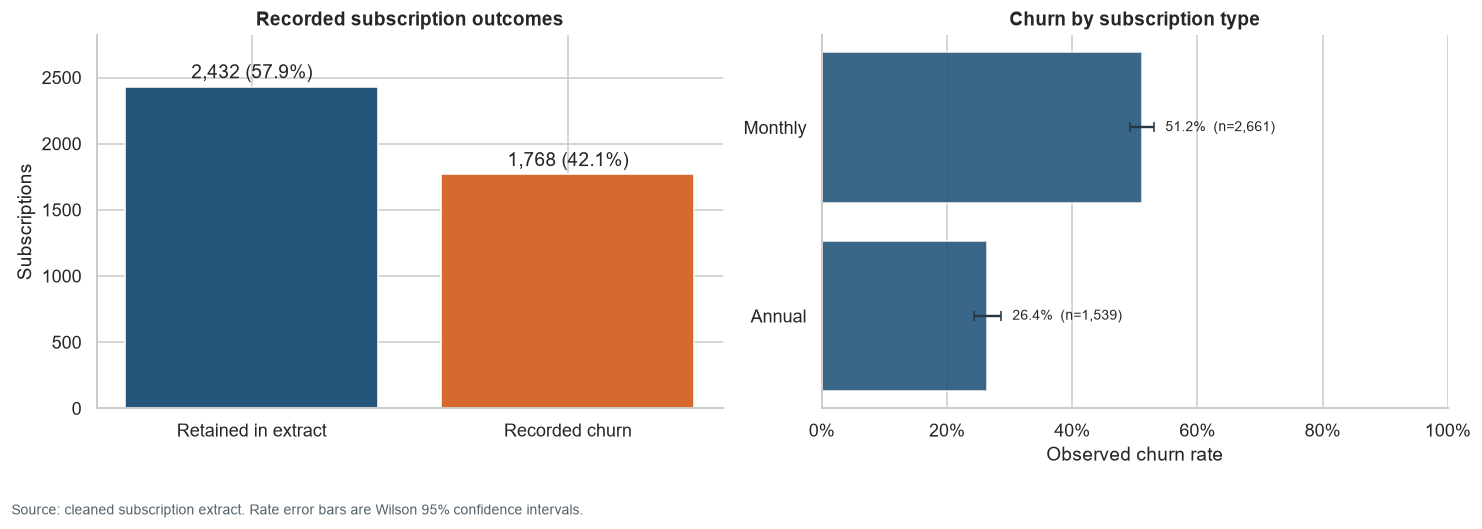

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
counts = df['churn_flag'].value_counts().reindex([0, 1], fill_value=0)
axes[0].bar(['Retained in extract', 'Recorded churn'], counts, color=[BLUE, ORANGE])
for i, count in enumerate(counts):
    axes[0].text(i, count+overall_n*.015, f'{count:,} ({count/overall_n:.1%})', ha='center')
axes[0].set(title='Recorded subscription outcomes', ylabel='Subscriptions', ylim=(0, counts.max()*1.16))
plot_rates(rate_table(df, 'plan_type').sort_values('rate', ascending=False),
           axes[1], 'Churn by subscription type')
finish_figure(fig, 'Source: cleaned subscription extract. Rate error bars are Wilson 95% confidence intervals.')

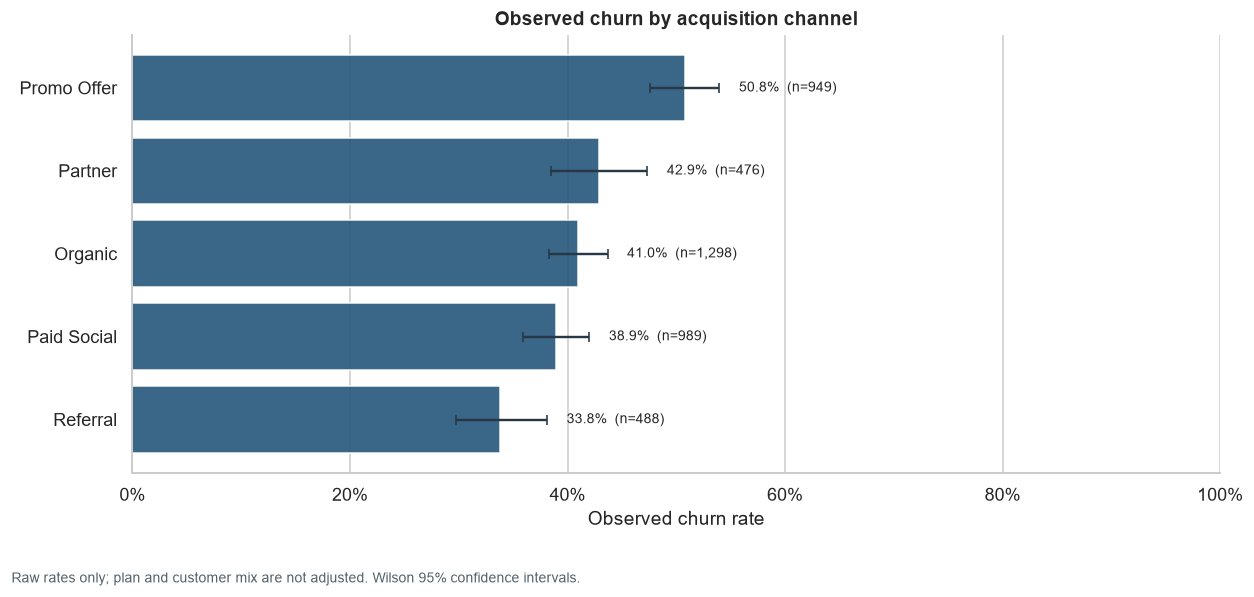

In [8]:
channel_rates = rate_table(df, 'acquisition_channel').sort_values('rate', ascending=False)
fig, ax = plt.subplots(figsize=(11, 5.2))
plot_rates(channel_rates, ax, 'Observed churn by acquisition channel')
finish_figure(fig, 'Raw rates only; plan and customer mix are not adjusted. Wilson 95% confidence intervals.')

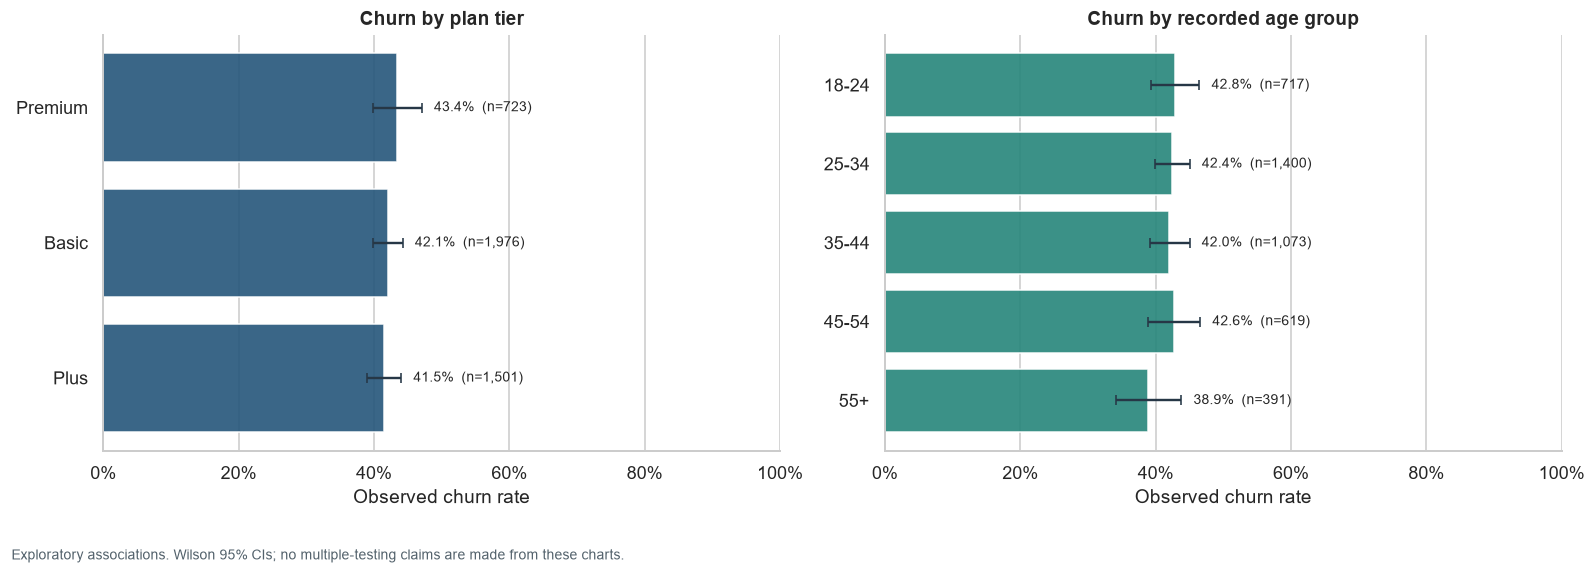

In [9]:
age_order = ['18-24', '25-34', '35-44', '45-54', '55+']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_rates(rate_table(df, 'plan_tier').sort_values('rate', ascending=False), axes[0], 'Churn by plan tier')
plot_rates(rate_table(df, 'age_group').reindex(age_order), axes[1], 'Churn by recorded age group', TEAL)
finish_figure(fig, 'Exploratory associations. Wilson 95% CIs; no multiple-testing claims are made from these charts.')

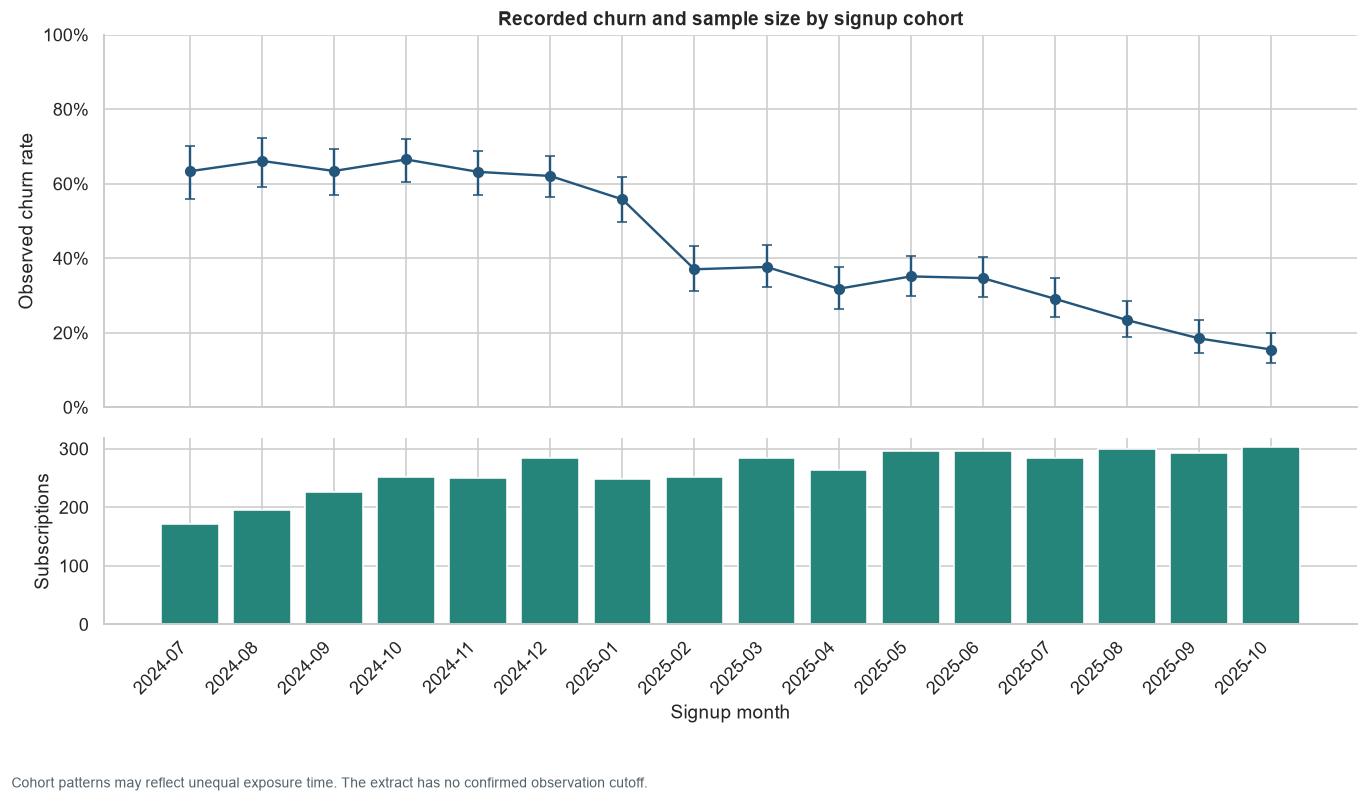

In [10]:
cohort_rates = rate_table(df, 'signup_cohort').sort_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
x = np.arange(len(cohort_rates))
axes[0].errorbar(x, cohort_rates['rate'],
    yerr=np.vstack([cohort_rates['rate']-cohort_rates['ci_low'], cohort_rates['ci_high']-cohort_rates['rate']]),
    marker='o', color=BLUE, capsize=3)
axes[0].set(title='Recorded churn and sample size by signup cohort', ylabel='Observed churn rate', ylim=(0, 1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].bar(x, cohort_rates['n'], color=TEAL)
axes[1].set(xticks=x, xticklabels=cohort_rates.index, ylabel='Subscriptions', xlabel='Signup month')
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
finish_figure(fig, 'Cohort patterns may reflect unequal exposure time. The extract has no confirmed observation cutoff.')

## 7. Statistical comparisons and effect sizes

Two prespecified comparisons contrast monthly promo-offer subscribers with (1) other monthly and
(2) annual promo-offer subscribers. All event/non-event counts are substantial, supporting two-sided
two-proportion z-tests. **Holm correction** controls family-wise error across these two tests at 0.05.

- **Risk difference:** absolute gap in percentage points; Newcombe interval combining Wilson intervals.
- **Risk ratio:** ratio of observed churn probabilities; log-scale interval.
- **Odds ratio:** ratio of churn odds, not probabilities; log-scale interval.

The 95% effect-size intervals are pointwise, not simultaneous family-wise intervals. Inference assumes
independent records and a meaningful sampling process. Unknown provenance limits generalization;
statistical evidence does not establish causality.

In [11]:
def compare_segments(table, group_a, group_b):
    a, b = table.loc[group_a], table.loc[group_b]
    n1, n0, c1, c0 = int(a['n']), int(b['n']), int(a['churned']), int(b['churned'])
    if min(c1, c0, n1-c1, n0-c0) < 5:
        raise ValueError('Sparse outcome cells: review test/interval methods before interpreting.')
    p1, p0 = c1/n1, c0/n0
    rd = p1-p0
    low = rd-np.sqrt((p1-a['ci_low'])**2+(b['ci_high']-p0)**2)
    high = rd+np.sqrt((a['ci_high']-p1)**2+(p0-b['ci_low'])**2)
    rr, odds = p1/p0, (c1/(n1-c1))/(c0/(n0-c0))
    rr_se = np.sqrt(1/c1-1/n1+1/c0-1/n0)
    or_se = np.sqrt(1/c1+1/(n1-c1)+1/c0+1/(n0-c0))
    _, p_value = proportions_ztest([c1, c0], [n1, n0], alternative='two-sided')
    return {'Comparison': f'{group_a} vs {group_b}', 'Risk difference (pp)': rd*100,
        'RD 95% low (pp)': low*100, 'RD 95% high (pp)': high*100,
        'Risk ratio': rr, 'RR 95% low': np.exp(np.log(rr)-Z_975*rr_se),
        'RR 95% high': np.exp(np.log(rr)+Z_975*rr_se),
        'Odds ratio': odds, 'OR 95% low': np.exp(np.log(odds)-Z_975*or_se),
        'OR 95% high': np.exp(np.log(odds)+Z_975*or_se), 'Raw p-value': p_value}

comparisons = pd.DataFrame([
    compare_segments(segment_rates, 'Monthly promo-offer', 'Other monthly'),
    compare_segments(segment_rates, 'Monthly promo-offer', 'Annual promo-offer'),
])
comparisons['Holm-adjusted p-value'] = multipletests(comparisons['Raw p-value'], method='holm')[1]
formats = {c: '{:.3f}' for c in comparisons.select_dtypes('number').columns}
formats.update({'Raw p-value': '{:.3e}', 'Holm-adjusted p-value': '{:.3e}'})
display(comparisons.style.format(formats))
for row in comparisons.to_dict('records'):
    evidence = 'below' if row['Holm-adjusted p-value'] < ALPHA else 'not below'
    print(f"{row['Comparison']}: {row['Risk difference (pp)']:.1f} pp "
          f"(95% CI {row['RD 95% low (pp)']:.1f} to {row['RD 95% high (pp)']:.1f}); "
          f"Holm p={row['Holm-adjusted p-value']:.3e}, {evidence} 0.05.")

,Comparison,Risk difference (pp),RD 95% low (pp),RD 95% high (pp),Risk ratio,RR 95% low,RR 95% high,Odds ratio,OR 95% low,OR 95% high,Raw p-value,Holm-adjusted p-value
0,Monthly promo-offer vs Other monthly,15.596,11.083,19.954,1.327,1.229,1.432,1.891,1.566,2.283,2.360e-11,2.360e-11
1,Monthly promo-offer vs Annual promo-offer,33.050,26.719,38.949,2.092,1.767,2.475,3.977,3.004,5.264,5.000e-23,9.999e-23


Monthly promo-offer vs Other monthly: 15.6 pp (95% CI 11.1 to 20.0); Holm p=2.360e-11, below 0.05.
Monthly promo-offer vs Annual promo-offer: 33.0 pp (95% CI 26.7 to 38.9); Holm p=9.999e-23, below 0.05.


## 8. Adjusted explanatory logistic regression

**Purpose:** Describe segment associations with recorded churn after accounting for available customer
mix. This full-sample explanatory analysis is separate from the out-of-fold classifier evaluation below.

The model includes `segment_group`, `plan_tier`, `primary_device`, `age_group`, and categorical
`signup_cohort`. Segment already represents plan plus promo/non-promo acquisition; those indicators
are not added again. `monthly_price` is omitted here because it is tied to plan and tier in this extract:
this specification does not identify a separate price effect. Differences between the pooled non-promo
channels remain a possible source of residual confounding.

`customer_id`, `churn_date`, and `cancel_reason` are never predictors. Signup cohort is not a substitute
for a known observation window. Device and other attributes need confirmed measurement timing before
future-prediction use.

Fit an unpenalized binomial GLM, check rank and convergence, and use HC1 robust covariance for
approximate Wald intervals. These intervals do not address unobserved confounding or misspecification.

In [12]:
adjusted_columns = ['segment_group', 'plan_tier', 'primary_device', 'age_group', 'signup_cohort']
adjusted_frame = df[adjusted_columns].copy()
# First level is the documented reference category.
adjusted_levels = {
    'segment_group': ['Other monthly', 'Monthly promo-offer', 'Annual promo-offer', 'Other annual'],
    'plan_tier': ['basic', 'plus', 'premium'],
    'primary_device': sorted(df['primary_device'].dropna().unique()),
    'age_group': age_order,
    'signup_cohort': sorted(df['signup_cohort'].dropna().unique()),
}
for column in adjusted_columns:
    if adjusted_frame[column].isna().any():
        raise ValueError(f'Missing {column}: document an inferential missing-data policy first.')
    if set(adjusted_frame[column])-set(adjusted_levels[column]):
        raise ValueError(f'Unexpected levels in {column}: review reference categories.')

def make_adjusted_design(frame):
    encoded = frame[adjusted_columns].copy()
    for column, levels in adjusted_levels.items():
        encoded[column] = pd.Categorical(encoded[column], categories=levels)
    encoded = pd.get_dummies(encoded, drop_first=True, dtype=float)
    return sm.add_constant(encoded, has_constant='add').astype(float)

adjusted_design = make_adjusted_design(adjusted_frame)
rank = np.linalg.matrix_rank(adjusted_design.to_numpy())
if rank != adjusted_design.shape[1]:
    raise ValueError('Adjusted design is not full rank; resolve redundant predictors.')
adjusted_fit = sm.GLM(df['churn_flag'], adjusted_design,
                      family=sm.families.Binomial()).fit(cov_type='HC1')
if not adjusted_fit.converged:
    raise RuntimeError('GLM did not converge; inspect the specification before interpreting.')
print(f'Converged: {adjusted_fit.converged}; observations: {int(adjusted_fit.nobs):,}; parameters: {rank}')
display(pd.DataFrame({'Reference category': {k: v[0] for k, v in adjusted_levels.items()}}))
display(pd.crosstab(df['segment_group'], df['plan_tier']).reindex(segment_order))
print('Nonzero group counts do not guarantee overlap in every covariate combination; extrapolation remains a limitation.')

Converged: True; observations: 4,200; parameters: 27


,Reference category
segment_group,Other monthly
plan_tier,basic
primary_device,android
age_group,18-24
signup_cohort,2024-07


plan_tier,basic,plus,premium
segment_group,,,
Monthly promo-offer,286,210,93
Other monthly,954,741,377
Annual promo-offer,177,117,66
Other annual,559,433,187


Nonzero group counts do not guarantee overlap in every covariate combination; extrapolation remains a limitation.


### 8.1 Conditional odds ratios

An odds ratio above 1 means higher odds of recorded churn relative to the reference category, conditional
on other modeled attributes. It is not a percentage-point increase, risk ratio, or causal effect.
The complete coefficient table includes cohort terms; the plot focuses on segment contrasts.
Intervals are exploratory pointwise 95% Wald intervals, not multiplicity-adjusted intervals.

,Log-odds coefficient,Odds ratio,95% CI low,95% CI high
segment_group_Monthly promo-offer,0.756,2.129,1.715,2.643
segment_group_Annual promo-offer,-0.884,0.413,0.327,0.523
segment_group_Other annual,-1.118,0.327,0.278,0.384
plan_tier_plus,-0.013,0.987,0.847,1.152
plan_tier_premium,0.050,1.051,0.866,1.275
primary_device_ios,-0.140,0.870,0.747,1.013
primary_device_web,-0.183,0.833,0.678,1.023
age_group_25-34,0.040,1.040,0.848,1.277
age_group_35-44,-0.051,0.951,0.767,1.178
age_group_45-54,0.072,1.075,0.842,1.373


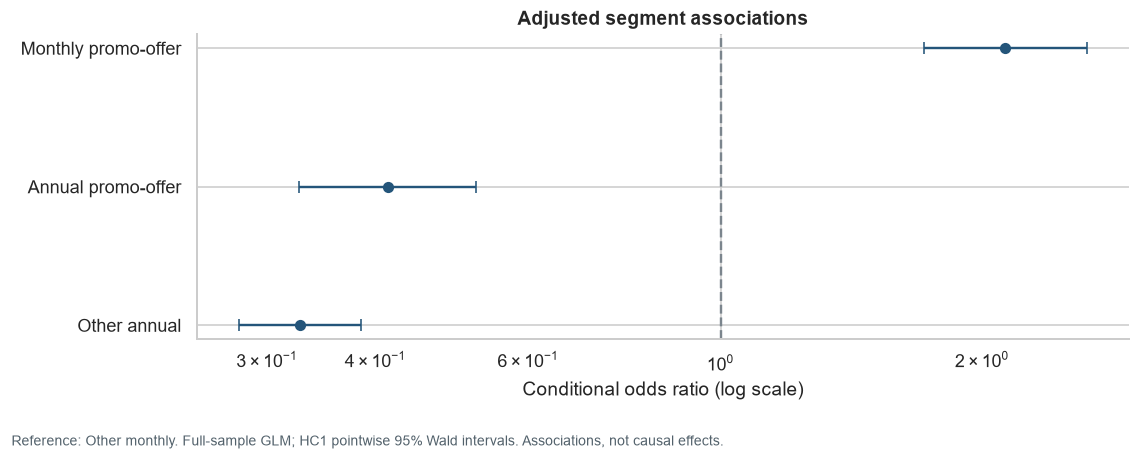

In [13]:
coefficient_ci = adjusted_fit.conf_int(alpha=ALPHA)
odds_table = pd.DataFrame({
    'Log-odds coefficient': adjusted_fit.params,
    'Odds ratio': np.exp(adjusted_fit.params),
    '95% CI low': np.exp(coefficient_ci[0]), '95% CI high': np.exp(coefficient_ci[1]),
}).drop(index='const')
display(odds_table.style.format('{:.3f}'))
segment_odds = odds_table.loc[odds_table.index.str.startswith('segment_group_')]
fig, ax = plt.subplots(figsize=(10, 4))
pos = np.arange(len(segment_odds))
ax.errorbar(segment_odds['Odds ratio'], pos,
    xerr=np.vstack([segment_odds['Odds ratio']-segment_odds['95% CI low'],
                   segment_odds['95% CI high']-segment_odds['Odds ratio']]),
    fmt='o', color=BLUE, capsize=4)
ax.axvline(1, color='#7B858D', linestyle='--')
ax.set(xscale='log', yticks=pos,
       yticklabels=segment_odds.index.str.replace('segment_group_', '', regex=False),
       xlabel='Conditional odds ratio (log scale)', title='Adjusted segment associations')
ax.invert_yaxis()
finish_figure(fig, 'Reference: Other monthly. Full-sample GLM; HC1 pointwise 95% Wald intervals. Associations, not causal effects.')

### 8.2 Standardized adjusted probabilities

Assign each segment in turn to every observed covariate profile, predict using the fitted model, and
average across the **same observed sample's covariate distribution**. This standardization makes estimates
comparable without inventing records or claiming experimental effects.

Approximate 95% intervals use the delta method and robust parameter covariance, on a logit scale to
remain within 0–1. The empirical covariate distribution is treated as fixed. Adjusted risk-difference
intervals use the covariance of both margins; they do not treat them as independent samples.

Results can differ from the earlier PDFs because the original model specification and standardization
population were not supplied. No historical adjusted probability is forced into the calculation.

In [14]:
adjusted_cov = adjusted_fit.cov_params().to_numpy()
adjusted_beta = adjusted_fit.params.to_numpy()
margins, margin_gradients = {}, {}
for segment in segment_order:
    scenario = adjusted_frame.copy()
    scenario['segment_group'] = segment
    design = make_adjusted_design(scenario).reindex(columns=adjusted_design.columns).to_numpy()
    individual_p = expit(design @ adjusted_beta)
    margin = individual_p.mean()
    gradient = (individual_p[:, None]*(1-individual_p[:, None])*design).mean(axis=0)
    se_margin = np.sqrt(max(float(gradient @ adjusted_cov @ gradient), 0))
    se_logit = se_margin/(margin*(1-margin))
    margins[segment] = {'Adjusted rate': margin,
        'Adjusted CI low': expit(logit(margin)-Z_975*se_logit),
        'Adjusted CI high': expit(logit(margin)+Z_975*se_logit)}
    margin_gradients[segment] = gradient
adjusted_rates = pd.DataFrame.from_dict(margins, orient='index')
observed_adjusted = segment_rates.join(adjusted_rates)
display(observed_adjusted.style.format({'n': '{:,.0f}', 'churned': '{:,.0f}',
    **{c: '{:.1%}' for c in ['rate', 'ci_low', 'ci_high',
                            'Adjusted rate', 'Adjusted CI low', 'Adjusted CI high']}}))

adjusted_differences = []
for other in ['Other monthly', 'Annual promo-offer']:
    difference = adjusted_rates.loc['Monthly promo-offer', 'Adjusted rate']-adjusted_rates.loc[other, 'Adjusted rate']
    gradient_difference = margin_gradients['Monthly promo-offer']-margin_gradients[other]
    se = np.sqrt(max(float(gradient_difference @ adjusted_cov @ gradient_difference), 0))
    adjusted_differences.append({'Comparison': f'Monthly promo-offer vs {other}',
        'Adjusted difference (pp)': difference*100,
        '95% low (pp)': (difference-Z_975*se)*100, '95% high (pp)': (difference+Z_975*se)*100})
display(pd.DataFrame(adjusted_differences).style.format(
    {c: '{:.2f}' for c in ['Adjusted difference (pp)', '95% low (pp)', '95% high (pp)']}))

,n,churned,rate,ci_low,ci_high,Adjusted rate,Adjusted CI low,Adjusted CI high
segment_group,,,,,,,,
Monthly promo-offer,589,373,63.3%,59.4%,67.1%,63.2%,59.3%,66.9%
Other monthly,"2,072",989,47.7%,45.6%,49.9%,47.4%,45.3%,49.5%
Annual promo-offer,360,109,30.3%,25.8%,35.2%,29.7%,26.0%,33.8%
Other annual,"1,179",297,25.2%,22.8%,27.7%,25.6%,23.5%,27.9%


,Comparison,Adjusted difference (pp),95% low (pp),95% high (pp)
0,Monthly promo-offer vs Other monthly,15.78,11.42,20.14
1,Monthly promo-offer vs Annual promo-offer,33.46,27.99,38.93


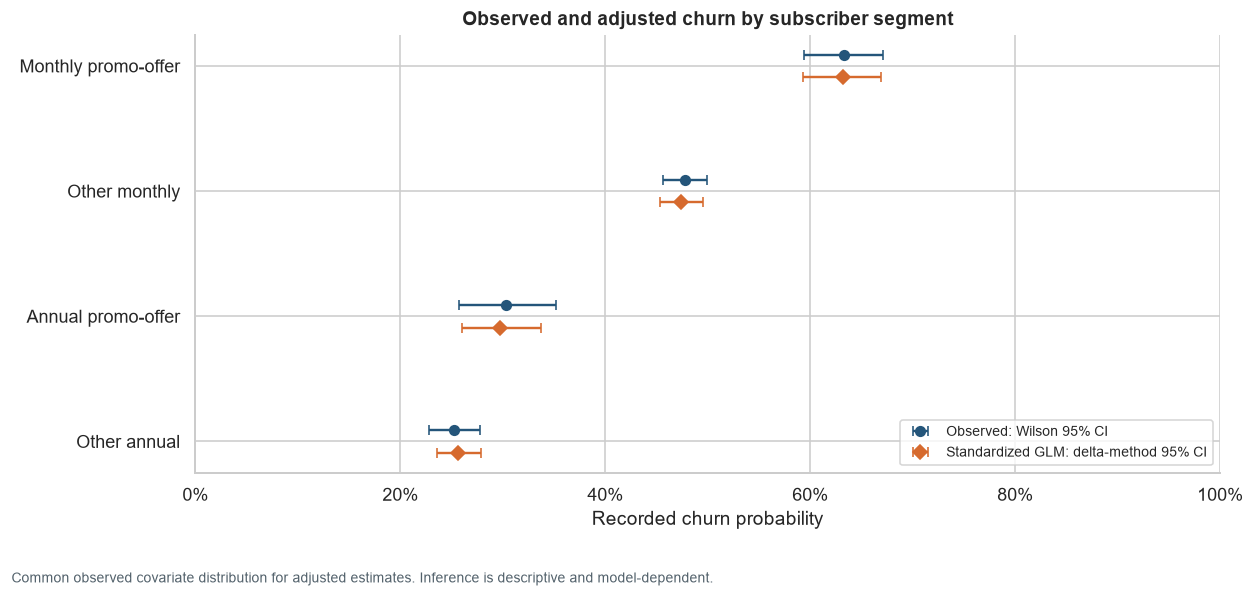

In [15]:
fig, ax = plt.subplots(figsize=(11, 5.2))
pos = np.arange(len(segment_order))
for offset, rate_col, low_col, high_col, label, color, marker in [
    (-.09, 'rate', 'ci_low', 'ci_high', 'Observed: Wilson 95% CI', BLUE, 'o'),
    (.09, 'Adjusted rate', 'Adjusted CI low', 'Adjusted CI high',
     'Standardized GLM: delta-method 95% CI', ORANGE, 'D'),
]:
    values = observed_adjusted[rate_col]
    ax.errorbar(values, pos+offset,
        xerr=np.vstack([values-observed_adjusted[low_col], observed_adjusted[high_col]-values]),
        fmt=marker, color=color, capsize=3, label=label)
ax.set(yticks=pos, yticklabels=segment_order, xlim=(0, 1), xlabel='Recorded churn probability',
       title='Observed and adjusted churn by subscriber segment')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
ax.legend(loc='lower right', fontsize=9)
finish_figure(fig, 'Common observed covariate distribution for adjusted estimates. Inference is descriptive and model-dependent.')

## 9. Build a leakage-aware classification pipeline

**Separate purpose:** Evaluate classification of recorded churn in held-out records. This is a fully
specified new model, not a reconstruction of undocumented PlotStudio settings.

| Numerical features | Categorical features |
| --- | --- |
| `monthly_price`, `signup_elapsed_months` | `plan_type`, `plan_tier`, `acquisition_channel`, `primary_device`, `age_group` |

Signup elapsed months encodes signup date relative to a fixed date and never uses churn timing.
Price is an available classification predictor, but its relationship to plan/tier prevents a simple
independent-price interpretation. Attribute availability at a real prediction date is not established.

**Excluded:** `customer_id`, target labels, `churn_date`, `cancel_reason`, and any outcome-timing-derived
feature. Segment labels are omitted because plan and channel are already included.

Training-fold-only imputation, numerical scaling, one-hot encoding, and regularized logistic regression
are in one pipeline. Use fixed `C=1.0`, no class reweighting or hyperparameter search, and threshold 0.50.

In [16]:
numeric_features = ['monthly_price', 'signup_elapsed_months']
categorical_features = ['plan_type', 'plan_tier', 'acquisition_channel', 'primary_device', 'age_group']
feature_columns = numeric_features+categorical_features
forbidden = {'customer_id', 'churned', 'churn_flag', 'churn_date', 'cancel_reason'}
assert not (set(feature_columns) & forbidden), 'Leakage or identifier column detected.'
X = df[feature_columns].copy().reset_index(drop=True)
y = df['churn_flag'].copy().reset_index(drop=True)
for column in categorical_features:
    X[column] = X[column].astype(object).where(X[column].notna(), np.nan)
preprocessing = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), numeric_features),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))]),
     categorical_features),
])
classifier = Pipeline([
    ('preprocess', preprocessing),
    ('logistic', LogisticRegression(C=1.0, solver='lbfgs', max_iter=3000, random_state=RANDOM_STATE)),
])
print('Predictors:', feature_columns)
print('Excluded:', sorted(forbidden))
print('Rows:', len(X), '| Positive class:', int(y.sum()), '| Threshold:', THRESHOLD)

Predictors: ['monthly_price', 'signup_elapsed_months', 'plan_type', 'plan_tier', 'acquisition_channel', 'primary_device', 'age_group']
Excluded: ['cancel_reason', 'churn_date', 'churn_flag', 'churned', 'customer_id']
Rows: 4200 | Positive class: 1768 | Threshold: 0.5


## 10. Evaluate with stratified 5-fold cross-validation

Five shuffled, stratified folds are identical across models. Every record receives exactly one prediction
from a model that did not train on it. Baselines are refit within each training fold:

- **Training-prevalence / majority baseline:** gives every validation record the training churn prevalence;
  at threshold 0.50 it predicts the training majority outcome.
- **Always-churn baseline:** flags everyone, showing the recall and F1 attainable by contacting all subscribers.

Report both the **mean and standard deviation across folds** and **pooled out-of-fold (OOF) metrics**.
These aggregations need not agree exactly. Fold standard deviations describe variation; they are not
confidence intervals. There is no untouched final test set: CV evaluates this fixed model specification,
not a future deployment or a data-driven model-selection process.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_names = ['Logistic regression', 'Training-prevalence baseline', 'Always-churn baseline']
oof_probabilities = {name: np.full(len(y), np.nan) for name in model_names}
fold_results = []
seen_as_validation = np.zeros(len(y), dtype=int)

def metric_scores(truth, probabilities):
    labels = (probabilities >= THRESHOLD).astype(int)
    return {'ROC-AUC': roc_auc_score(truth, probabilities),
        'Precision': precision_score(truth, labels, zero_division=0),
        'Recall': recall_score(truth, labels, zero_division=0),
        'F1-score': f1_score(truth, labels, zero_division=0),
        'Average precision': average_precision_score(truth, probabilities)}

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):
    assert not len(np.intersect1d(train_index, validation_index))
    seen_as_validation[validation_index] += 1
    fitted = clone(classifier).fit(X.iloc[train_index], y.iloc[train_index])
    probabilities = {'Logistic regression': fitted.predict_proba(X.iloc[validation_index])[:, 1]}
    for name, baseline in [
        ('Training-prevalence baseline', DummyClassifier(strategy='prior')),
        ('Always-churn baseline', DummyClassifier(strategy='constant', constant=1)),
    ]:
        baseline.fit(np.zeros((len(train_index), 1)), y.iloc[train_index])
        positive_column = np.flatnonzero(baseline.classes_ == 1)[0]
        probabilities[name] = baseline.predict_proba(np.zeros((len(validation_index), 1)))[:, positive_column]
    for name, scores in probabilities.items():
        oof_probabilities[name][validation_index] = scores
        fold_results.append({'Fold': fold, 'Model': name,
            'Training n': len(train_index), 'Validation n': len(validation_index),
            **metric_scores(y.iloc[validation_index], scores)})

assert (seen_as_validation == 1).all()
assert all(np.isfinite(p).all() for p in oof_probabilities.values())
fold_metrics = pd.DataFrame(fold_results)
oof_summary = pd.DataFrame({name: metric_scores(y, p) for name, p in oof_probabilities.items()}).T
metric_columns = ['ROC-AUC', 'Precision', 'Recall', 'F1-score', 'Average precision']
cv_summary = fold_metrics.groupby('Model')[metric_columns].agg(['mean', 'std'])
display(Markdown('**Per-fold results**'))
display(fold_metrics.style.format({c: '{:.3f}' for c in metric_columns}))
display(Markdown('**CV mean and fold standard deviation**'))
display(cv_summary.style.format('{:.3f}'))
display(Markdown('**Pooled OOF results at threshold 0.50**'))
display(oof_summary.style.format('{:.3f}'))

**Per-fold results**

,Fold,Model,Training n,Validation n,ROC-AUC,Precision,Recall,F1-score,Average precision
0,1,Logistic regression,3360,840,0.753,0.628,0.525,0.572,0.640
1,1,Training-prevalence baseline,3360,840,0.500,0.000,0.000,0.000,0.421
2,1,Always-churn baseline,3360,840,0.500,0.421,1.000,0.593,0.421
3,2,Logistic regression,3360,840,0.742,0.608,0.531,0.567,0.617
4,2,Training-prevalence baseline,3360,840,0.500,0.000,0.000,0.000,0.421
5,2,Always-churn baseline,3360,840,0.500,0.421,1.000,0.593,0.421
6,3,Logistic regression,3360,840,0.749,0.634,0.534,0.580,0.663
7,3,Training-prevalence baseline,3360,840,0.500,0.000,0.000,0.000,0.421
8,3,Always-churn baseline,3360,840,0.500,0.421,1.000,0.593,0.421
9,4,Logistic regression,3360,840,0.739,0.598,0.527,0.560,0.618


**CV mean and fold standard deviation**

**Pooled OOF results at threshold 0.50**

,ROC-AUC,Precision,Recall,F1-score,Average precision
Logistic regression,0.748,0.622,0.525,0.570,0.638
Training-prevalence baseline,0.499,0.000,0.000,0.000,0.421
Always-churn baseline,0.500,0.421,1.000,0.592,0.421


### 10.1 Interpret the evaluation metrics

| Metric | Plain-English meaning |
| --- | --- |
| ROC-AUC | How often a churned subscription ranks above a non-churned one; 0.5 means chance ranking. |
| Precision | Of subscriptions flagged as churned, how many actually have recorded churn? |
| Recall | Of subscriptions with recorded churn, how many are flagged? |
| F1-score | A harmonic balance between precision and recall at the selected threshold. |
| Average precision | Summary of precision across recall levels; the constant-score population baseline is churn prevalence. |

Flagging everyone can produce a strong F1 baseline but low precision and excessive contact volume.
Choose business criteria using capacity, intervention cost, and measured treatment effects. Threshold
selection must occur within training/validation, then be evaluated on untouched data.

The training-prevalence baseline has ROC-AUC 0.5 **within every fold**. Pooling slightly different
training prevalence scores can produce OOF AUC below 0.5 because those scores vary inversely with
held-out fold prevalence. Per-fold results are the appropriate reference for its ranking ability.

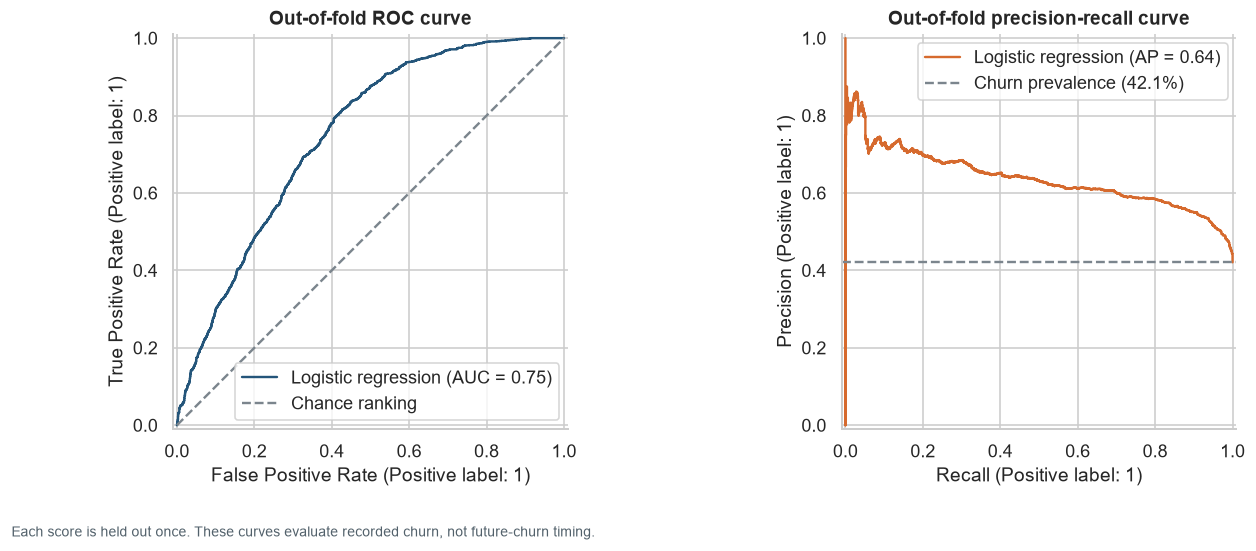

In [18]:
logistic_oof = oof_probabilities['Logistic regression']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
RocCurveDisplay.from_predictions(y, logistic_oof, ax=axes[0],
    curve_kwargs={'color': BLUE}, name='Logistic regression')
axes[0].plot([0, 1], [0, 1], '--', color='#7B858D', label='Chance ranking')
axes[0].set_title('Out-of-fold ROC curve')
axes[0].legend(loc='lower right')
PrecisionRecallDisplay.from_predictions(y, logistic_oof, ax=axes[1],
    curve_kwargs={'color': ORANGE}, name='Logistic regression')
axes[1].axhline(y.mean(), linestyle='--', color='#7B858D', label=f'Churn prevalence ({y.mean():.1%})')
axes[1].set_title('Out-of-fold precision-recall curve')
axes[1].legend(loc='upper right')
finish_figure(fig, 'Each score is held out once. These curves evaluate recorded churn, not future-churn timing.')

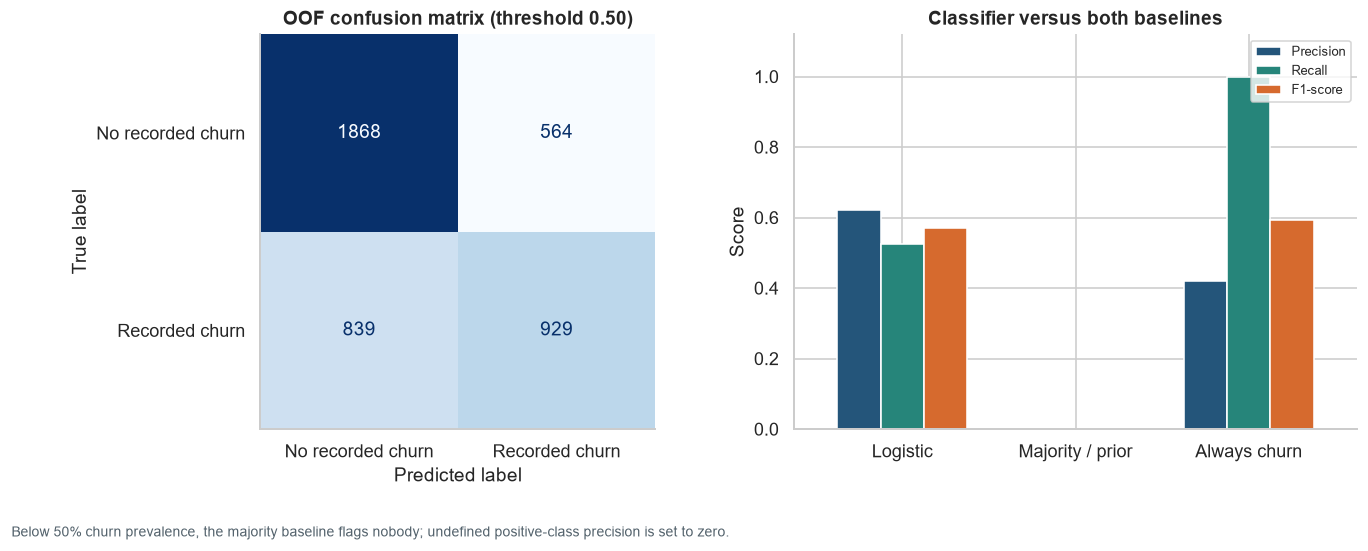

In [19]:
logistic_labels = (logistic_oof >= THRESHOLD).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(y, logistic_labels, ax=axes[0],
    display_labels=['No recorded churn', 'Recorded churn'], cmap='Blues', colorbar=False, values_format='d')
axes[0].grid(False)
axes[0].set_title('OOF confusion matrix (threshold 0.50)')
metric_plot = oof_summary[['Precision', 'Recall', 'F1-score']].copy()
metric_plot.index = ['Logistic', 'Majority / prior', 'Always churn']
metric_plot.plot.bar(ax=axes[1], color=[BLUE, TEAL, ORANGE], rot=0, width=.75)
axes[1].set(title='Classifier versus both baselines', ylabel='Score', ylim=(0, 1.12), xlabel='')
axes[1].legend(loc='upper right', fontsize=8)
finish_figure(fig, 'Below 50% churn prevalence, the majority baseline flags nobody; undefined positive-class precision is set to zero.')

## 11. Reconcile recalculated scores with historical project metrics

Previously reported ROC-AUC **0.751**, precision **0.637**, recall **0.502**, and F1 **0.562** are
**reference values only**. The table compares them with independently calculated OOF scores and CV
means, flagging differences at the original three-decimal reporting precision.

Differences may reflect predictor selection, preprocessing, regularization, fold allocation, threshold,
or averaging method. Original fitted models, fold assignments, and settings are unavailable, so this
notebook cannot identify which explanation applies. Settings are never adjusted to force agreement.

In [20]:
reported_metrics = pd.Series({'ROC-AUC': .751, 'Precision': .637, 'Recall': .502, 'F1-score': .562},
                             name='Previously reported (reference only)')
metric_reconciliation = reported_metrics.to_frame()
metric_reconciliation['Recalculated pooled OOF'] = oof_summary.loc['Logistic regression', reported_metrics.index]
metric_reconciliation['Recalculated CV mean'] = [
    cv_summary.loc['Logistic regression', (m, 'mean')] for m in reported_metrics.index]
metric_reconciliation['CV fold standard deviation'] = [
    cv_summary.loc['Logistic regression', (m, 'std')] for m in reported_metrics.index]
metric_reconciliation['OOF minus reported'] = metric_reconciliation['Recalculated pooled OOF']-reported_metrics
metric_reconciliation['OOF matches published 3 decimals'] = (
    metric_reconciliation['Recalculated pooled OOF'].round(3).eq(reported_metrics))
display(metric_reconciliation.style.format(
    {c: '{:.3f}' for c in metric_reconciliation.select_dtypes('number').columns}))
if not metric_reconciliation['OOF matches published 3 decimals'].all():
    display(Markdown('**This model does not exactly reproduce all historical scores.** '
        'Use the executed results with their stated protocol; retain old scores only as historical references.'))
best_baseline_f1 = oof_summary.loc[model_names[1:], 'F1-score'].max()
model_f1 = oof_summary.loc['Logistic regression', 'F1-score']
comparison_text = 'exceeds' if model_f1 > best_baseline_f1 else 'does not exceed'
print(f'Logistic OOF F1 {model_f1:.3f} {comparison_text} the best baseline F1 {best_baseline_f1:.3f}.')
print('Also consider precision, recall, ranking quality, contact capacity, and intervention outcomes.')

,Previously reported (reference only),Recalculated pooled OOF,Recalculated CV mean,CV fold standard deviation,OOF minus reported,OOF matches published 3 decimals
ROC-AUC,0.751,0.748,0.748,0.008,-0.003,False
Precision,0.637,0.622,0.623,0.019,-0.015,False
Recall,0.502,0.525,0.525,0.009,0.023,False
F1-score,0.562,0.570,0.570,0.007,0.008,False


**This model does not exactly reproduce all historical scores.** Use the executed results with their stated protocol; retain old scores only as historical references.

Logistic OOF F1 0.570 does not exceed the best baseline F1 0.592.
Also consider precision, recall, ranking quality, contact capacity, and intervention outcomes.


## 12. Recommend retention experiments

Elevated observed churn motivates investigation, not a causal diagnosis or a promise of retention gains.
When the verified rates and adjusted analysis support the ordering, prioritize monthly promotional
subscribers for controlled retention tests.

| Experiment | Eligibility and randomization | Treatment hypothesis | Outcomes and guardrails |
| --- | --- | --- | --- |
| Early onboarding support | New monthly promo-offer subscribers; randomize at signup | Guided setup and early check-ins improve activation and retention | Renewal/churn at a prespecified horizon; engagement secondary; support cost and opt-outs |
| Promotion framing or eligibility | Comparable prospects; randomize framing/eligibility, keeping price constant where feasible | Acquisition messaging changes fit and expectations | Retained subscribers per randomized prospect and acquisition cost; churn among signups secondary because treatment changes who signs up |
| Renewal support | Eligible monthly promo subscribers before a defined renewal; randomize outreach | Timely reminders and support resolve avoidable barriers | Renewal/churn, contact cost, complaints, and discount spending where applicable |

**Design before launch:** Define the randomization unit, eligibility, a control group, one primary
outcome, assignment date, fixed follow-up, and minimum meaningful effect. Calculate sample size from
that effect and a relevant baseline. Analyze by randomized assignment (intention to treat), allow full
follow-up, and report confidence intervals. Do not treat the observed segment gap as a treatment effect
or invent revenue savings.

## 13. Limitations and next steps

- **Provenance and measurement:** Original publisher, real/synthetic status, sampling process, extract
  cutoff, and feature measurement timing are not established. Confirm them before generalizing.
- **Unequal exposure:** Signup/churn dates exist, but the censoring date for retained subscribers does
  not. Rates mix different opportunities to churn. Cohort adjustment does not fully solve this.
- **Association, not causation:** Engagement, intent, plan selection, and acquisition mix can confound
  comparisons. Adjustment depends on specification and covariate overlap.
- **Missing reasons:** Some churned records lack usable cancellation reasons. Dates and reasons remain
  excluded from every model and cannot be used to claim knowledge of individual churn causes.
- **Validation scope:** Random stratified CV describes classification within a similar extract, not
  future temporal performance, repeated-customer settings, or intervention effectiveness.
- **Inference scope:** Intervals assume independent records. Coefficient and marginal intervals are
  pointwise; Holm correction applies only to the two prespecified raw comparison tests.
- **Next prediction study:** Define a prediction date and outcome window, reconstruct features
  available at that date, collect engagement history, and validate on a later untouched cohort.
  Use group-aware splits if subscribers repeat. Assess calibration and contact capacity; select
  thresholds inside training data, then evaluate once on untouched data.
- **Business value:** Randomize interventions. Estimate incremental retention, cost per incremental
  retained subscriber, and net value from observed treatment outcomes rather than classification scores.

## 14. Executive summary

This summary is generated from the executed calculations, including verification results and baseline comparisons.

In [21]:
monthly_promo = segment_rates.loc['Monthly promo-offer']
other_monthly = segment_rates.loc['Other monthly']
annual_promo = segment_rates.loc['Annual promo-offer']
raw_gap = (monthly_promo['rate']-other_monthly['rate'])*100
adjusted_highest = adjusted_rates['Adjusted rate'].idxmax()
metrics = oof_summary.loc['Logistic regression']
tn, fp, fn, tp = confusion_matrix(y, logistic_labels, labels=[0, 1]).ravel()
verification_note = ('All published descriptive counts and rounded rates match the input CSV.'
    if all_descriptive_verified else 'Published descriptive findings differ from this CSV; resolve the flagged discrepancies.')
f1_note = 'exceeds' if metrics['F1-score'] > best_baseline_f1 else 'does not exceed'
summary = f'''
**Business finding.** Of **{overall_n:,}** records, **{overall_churned:,}** have recorded churn:
**{overall_rate:.1%}** (Wilson 95% CI **{overall_ci[0]:.1%} to {overall_ci[1]:.1%}**).
{verification_note}

- **Monthly promo-offer:** {monthly_promo['n']:,.0f} subscriptions; **{monthly_promo['rate']:.1%}** observed churn.
- **Other monthly:** {other_monthly['n']:,.0f} subscriptions; **{other_monthly['rate']:.1%}** observed churn.
- **Annual promo-offer:** {annual_promo['n']:,.0f} subscriptions; **{annual_promo['rate']:.1%}** observed churn.

Monthly promo subscribers have a **{raw_gap:.1f}-percentage-point** observed gap versus other monthly
subscribers. The adjusted model's highest standardized estimate is **{adjusted_highest}**.
These associations do not identify a causal treatment effect.

**Classification.** The independently specified pipeline produces pooled out-of-fold
**ROC-AUC {metrics['ROC-AUC']:.3f}**, **precision {metrics['Precision']:.3f}**,
**recall {metrics['Recall']:.3f}**, and **F1 {metrics['F1-score']:.3f}** at threshold {THRESHOLD:.2f}.
It flags **{tp+fp:,}** records, including **{tp:,}** recorded churn cases, and misses **{fn:,}**.
Its F1 {f1_note} the best simple baseline (**{best_baseline_f1:.3f}**).
Historical scores remain reference values; see the explicit reconciliation table.

**Recommended action.** Test onboarding and renewal support for monthly promotional subscribers with
randomized controls and a fixed follow-up window. Evaluate promotion design while accounting for
selection into signup. Measure incremental retention and intervention cost before expanding outreach.

**Readiness.** This notebook supports reproducible retrospective analysis. Deployment for future churn
requires documented feature timing, a defined prediction date and outcome window, later-cohort
validation, and evidence that interventions improve outcomes.
'''
display(Markdown(summary))


**Business finding.** Of **4,200** records, **1,768** have recorded churn:
**42.1%** (Wilson 95% CI **40.6% to 43.6%**).
All published descriptive counts and rounded rates match the input CSV.

- **Monthly promo-offer:** 589 subscriptions; **63.3%** observed churn.
- **Other monthly:** 2,072 subscriptions; **47.7%** observed churn.
- **Annual promo-offer:** 360 subscriptions; **30.3%** observed churn.

Monthly promo subscribers have a **15.6-percentage-point** observed gap versus other monthly
subscribers. The adjusted model's highest standardized estimate is **Monthly promo-offer**.
These associations do not identify a causal treatment effect.

**Classification.** The independently specified pipeline produces pooled out-of-fold
**ROC-AUC 0.748**, **precision 0.622**,
**recall 0.525**, and **F1 0.570** at threshold 0.50.
It flags **1,493** records, including **929** recorded churn cases, and misses **839**.
Its F1 does not exceed the best simple baseline (**0.592**).
Historical scores remain reference values; see the explicit reconciliation table.

**Recommended action.** Test onboarding and renewal support for monthly promotional subscribers with
randomized controls and a fixed follow-up window. Evaluate promotion design while accounting for
selection into signup. Measure incremental retention and intervention cost before expanding outreach.

**Readiness.** This notebook supports reproducible retrospective analysis. Deployment for future churn
requires documented feature timing, a defined prediction date and outcome window, later-cohort
validation, and evidence that interventions improve outcomes.


## 15. Reproducibility record and method references

The input hash and tested package versions are recorded below. The accompanying `requirements.txt`
pins the analysis and notebook execution packages used here. Platform, transitive package releases,
and numerical libraries can still produce small differences.

- [pandas documentation](https://pandas.pydata.org/docs/): inspection and tabulation.
- [statsmodels proportion intervals](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html)
  and [binomial GLM](https://www.statsmodels.org/stable/glm.html): Wilson intervals and logistic modeling.
- [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage):
  fit preprocessing within training folds.
- [scikit-learn cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
  and [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html): held-out metrics.

References describe methods. The project's actual CSV supplies the calculated results.

In [22]:
execution_packages = packages+['nbformat', 'nbclient', 'nbconvert', 'ipykernel']
print('Input SHA-256:', file_sha256)
print('Matches source snapshot:', file_sha256 == REFERENCE_SHA256)
print('Python:', platform.python_version())
print('Seed:', RANDOM_STATE, '| CV: shuffled stratified 5-fold | Threshold:', THRESHOLD)
display(pd.DataFrame({'Package': execution_packages,
                      'Version': [metadata.version(p) for p in execution_packages]}))
print('No historical model score is used as a computed model output.')

Input SHA-256: 3c9603591440a4efd051e5468cde5d144d76145912851955dd2d4b2e65ece773
Matches source snapshot: True
Python: 3.12.14
Seed: 42 | CV: shuffled stratified 5-fold | Threshold: 0.5


,Package,Version
0,pandas,3.1.0
1,numpy,2.5.4
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,scikit-learn,1.9.1
5,scipy,1.18.1
6,statsmodels,0.15.0
7,nbformat,5.11.1
8,nbclient,0.11.0
9,nbconvert,7.17.2


No historical model score is used as a computed model output.
